In [2]:
import os
import glob

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="talk")

In [ ]:
# =========================
# DATA INPUT
# =========================

DATA_FOLDER = "/"

conditions = {
    "file_1": {"label": "Control", "colour": "#808080"},
    "file_2": {"label": "PEG10K 2 wt%", "colour": "#6CB0D6"},
    "file_3": {"label": "PEG10K 5 wt%", "colour": "#226E9C"},
    "file_4": {"label": "PEG10K 10 wt%", "colour": "#0D4A70"}

}

TIME_COLUMN = "Time [s]"
VOLUME_COLUMN = "Volume [µm^3]"

TIME_BIN = 30
SUMMARY_QUANTILE = 0.90

In [4]:
# =========================
# LOAD DATA + PEAK ALIGNMENT
# =========================

all_data = []

for prefix, info in conditions.items():

    files = sorted(glob.glob(os.path.join(DATA_FOLDER, f"{prefix}*.csv")))

    for file in files:

        df = pd.read_csv(file)

        df["Replicate"] = os.path.basename(file)
        df["Condition"] = info["label"]
        df["Colour"] = info["colour"]

        # absolute time
        df["Time_abs"] = df[TIME_COLUMN]

        v = df[VOLUME_COLUMN].values
        t = df["Time_abs"].values

        # -------------------------
        # peak detection per replicate
        # -------------------------
        peak_idx = np.nanargmax(v)
        t_peak = t[peak_idx]

        df["t_peak"] = t_peak  # store for later averaging step

        all_data.append(df)

# concatenate everything
data = pd.concat(all_data, ignore_index=True)

print(data.head())

# =========================
# COMPUTE MEAN PEAK TIME PER CONDITION
# =========================

peak_means = (
    data
    .groupby("Condition")["t_peak"]
    .mean()
    .to_dict()
)

# =========================
# PEAK-ALIGNED TIME (SHIFTED TO CONDITION MEAN PEAK)
# =========================

data["Time_peak_aligned"] = (
    data["Time_abs"]
    - data["t_peak"]
    + data["Condition"].map(peak_means)
)


   Droplet ID                   File  Experiment  Slice number  Time [s]  \
0           1  PKU_041_2min21sec.tif          41             1     141.0   
1           2  PKU_041_2min21sec.tif          41             1     141.0   
2           3  PKU_041_2min21sec.tif          41             1     141.0   
3           4  PKU_041_2min21sec.tif          41             1     141.0   
4           5  PKU_041_2min21sec.tif          41             1     141.0   

   Radius [µm]  Area [µm^2]  Circularity  Volume [µm^3]  \
0     0.974243     2.356335     0.641141       3.873385   
1     0.542753     1.047260     0.857372       0.669724   
2     1.054889     3.403594     0.833556       4.917091   
3     1.667904     8.378079     0.815283      19.435781   
4     0.665217     1.701797     0.898353       1.233044   

                              Replicate Condition   Colour  Time_abs  \
0  PKU_041-02min21sec_droplet_level.csv   Control  #808080     141.0   
1  PKU_041-02min21sec_droplet_level.csv   Co

In [ ]:
# =========================
# SCATTER PLOT
# =========================

palette = {
    info["label"]: info["colour"]
    for info in conditions.values()
}

plt.figure(figsize=(10,7))

sns.scatterplot(
    data=data,
    x="Time_peak_aligned",
    y=VOLUME_COLUMN,
    hue="Condition",
    palette=palette,
    alpha=0.75,
    s=18,
    linewidth=0
)

plt.xlabel("Time (s)")
plt.ylabel("Droplet volume ($\\mu$m$^3$)")
# plt.title("Peak-aligned droplet trajectories (scatter)")

plt.ylim(0, 600)

plt.legend(frameon=False)
plt.tight_layout()
plt.show()

IndentationError: unexpected indent (3920968844.py, line 4)

In [ ]:
# =========================
# DATA SUMMARY AND QUANTILE
# =========================

data["Time_bin"] = np.round(data["Time_peak_aligned"] / TIME_BIN) * TIME_BIN

summary = (
    data
    .groupby(["Condition", "Replicate", "Time_bin"])[VOLUME_COLUMN]
    .quantile(SUMMARY_QUANTILE)
    .reset_index(name="Volume90")
)

summary.head()

mean_summary = (
    summary
    .groupby(["Condition", "Time_bin"])
    .agg(
        Mean=("Volume90", "mean"),
        SD=("Volume90", "std"),
        N=("Volume90", "count")
    )
    .reset_index()
)

mean_summary["SEM"] = mean_summary["SD"] / np.sqrt(mean_summary["N"])

NameError: name 'np' is not defined

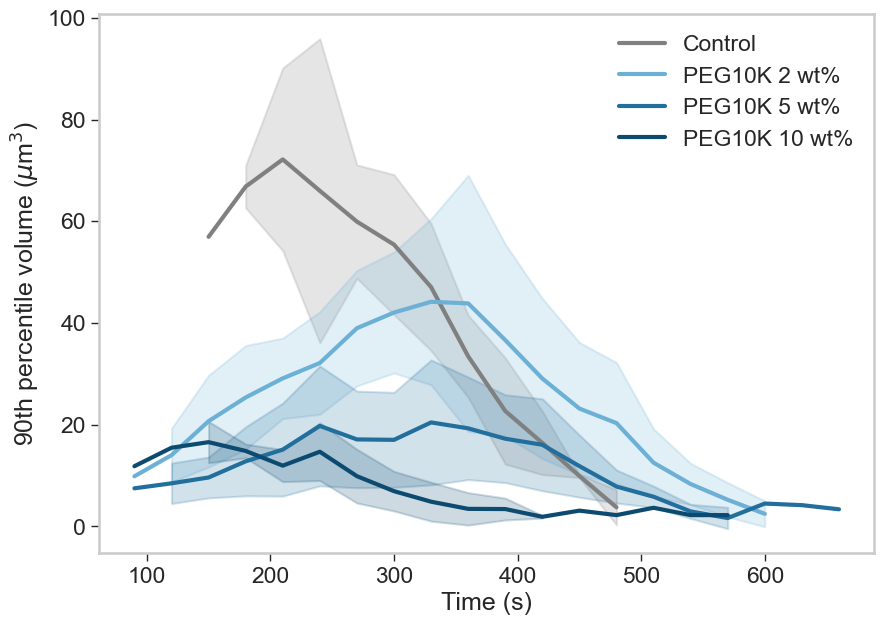

In [ ]:
# =========================
# 90TH PERCENTILE PLOT
# =========================

fig, ax = plt.subplots(figsize=(10,7))

for condition in palette:

    df = mean_summary[mean_summary["Condition"] == condition]
    df = df.sort_values("Time_bin")

    ax.plot(
        df["Time_bin"],
        df["Mean"],
        color=palette[condition],
        lw=3,
        label=condition
    )

    ax.fill_between(
        df["Time_bin"],
        df["Mean"] - df["SD"],
        df["Mean"] + df["SD"],
        alpha=0.2,
        color=palette[condition]
    )

ax.set_xlabel("Time (s)")
ax.set_ylabel("90th percentile volume ($\\mu$m$^3$)")

# Force visible major ticks
ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    length=6,
    width=1,
    bottom=True,
    left=True
)

plt.legend(frameon=False)
plt.grid(False)

plt.show()

In [ ]:
# ============================================
# EXPORT 90th PERCENTILE VOLUME
# ============================================

# Clean replicate names
export_90th = summary[
    ["Condition", "Replicate", "Time_bin", "Volume90"]
].copy()

export_90th["Replicate"] = (
    export_90th["Replicate"]
    .str.replace("_droplet_level.csv", "", regex=False)
)

# Give each replicate a consistent number within each condition
export_90th["Replicate_number"] = (
    export_90th
    .groupby("Condition")["Replicate"]
    .transform(lambda x: pd.factorize(x)[0] + 1)
)

# Reshape:
# rows    = Condition + Time
# columns = Replicate 1, Replicate 2, Replicate 3
wide_90th = (
    export_90th
    .pivot_table(
        index=["Condition", "Time_bin"],
        columns="Replicate_number",
        values="Volume90",
        aggfunc="first"
    )
    .reset_index()
)

# Rename replicate columns
wide_90th = wide_90th.rename(
    columns={
        1: "Replicate 1",
        2: "Replicate 2",
        3: "Replicate 3"
    }
)

# Sort conditions and time
condition_order = list(conditions.values())
condition_order = [x["label"] for x in condition_order]

wide_90th["Condition"] = pd.Categorical(
    wide_90th["Condition"],
    categories=condition_order,
    ordered=True
)

wide_90th = (
    wide_90th
    .sort_values(["Condition", "Time_bin"])
    .reset_index(drop=True)
)

# Save CSV
output_file = os.path.join(
    DATA_FOLDER,
    "droplet_volume_90th_percentile_triplicates_wide.csv"
)

wide_90th.to_csv(output_file, index=False)

print(f"Saved to:\n{output_file}")
print("\nPreview:")
display(wide_90th.head(15))

Saved to:
/Users/parth/dev/boekhoven_lab/data/W1_volume/droplet_volume_90th_percentile_triplicates_wide.csv

Preview:


Replicate_number,Condition,Time_bin,Replicate 1,Replicate 2,Replicate 3
0,Control,150.0,56.940041,NaN,NaN
1,Control,180.0,70.917010,62.554864,66.966010
2,Control,210.0,59.892645,92.792534,63.812469
3,Control,240.0,98.032890,38.840342,61.091595
4,Control,270.0,72.793797,53.976327,53.017572
5,Control,300.0,71.201759,49.016308,46.010190
6,Control,330.0,61.197619,42.456699,37.517921
7,Control,360.0,39.652205,36.364446,24.325056
8,Control,390.0,29.989981,27.368045,10.716903
9,Control,420.0,12.006278,20.823703,NaN
